# ⚡ EnergyMind Tunisia — Dataset Presentation

A quick tour of **`energymind_full_joined.csv.gz`**: smart-meter readings from three simulated Tunisian neighborhoods, with injected faults and the correct labels.

> One row = **one smart meter during one 30-minute interval** (year 2025). The data is **simulated**; the `gt_*` columns are the correct answers.

## 1. Load

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv("../data/energymind_full_joined.csv.gz", parse_dates=["timestamp"], low_memory=False)
n_cols = df.shape[1]
df["hour"] = df.timestamp.dt.hour + df.timestamp.dt.minute / 60
df["month"] = df.timestamp.dt.month

print(f"{len(df):,} rows x {n_cols} columns | {df.meter_id.nunique()} meters | "
      f"{df.feeder_id.nunique()} feeders | {df.node_id.nunique()} nodes")
print(df.timestamp.min(), "->", df.timestamp.max())
df[["timestamp", "meter_id", "energy_kwh", "voltage_v", "current_a", "power_factor", "temp_c", "gt_label"]].head()

1,051,200 rows x 67 columns | 60 meters | 7 feeders | 3 nodes
2025-01-01 00:00:00 -> 2025-12-31 23:30:00


,timestamp,meter_id,energy_kwh,voltage_v,current_a,power_factor,temp_c,gt_label
0,2025-01-01,N1-M001,0.085,233.8,0.75,0.951,8.3,normal
1,2025-01-01,N1-M002,0.055,233.5,0.51,0.934,8.3,normal
2,2025-01-01,N1-M003,0.049,233.6,0.46,0.928,8.3,normal
3,2025-01-01,N1-M004,0.320,233.1,2.78,0.980,8.3,normal
4,2025-01-01,N1-M005,0.079,233.7,0.72,0.940,8.3,normal


## 2. The 67 columns in six groups

In [2]:
groups = {
    "Identifiers":        ["timestamp", "node_id", "feeder_id", "meter_id"],
    "Meter measurements": ["energy_kwh", "pv_export_kwh", "reactive_kvarh", "voltage_v", "voltage_min_v", "voltage_max_v",
                           "current_a", "power_factor", "thd_v_pct", "meter_event_code"],
    "Meter details":      ["phase", "customer_class", "dwelling_type", "floor_area_m2", "occupants", "distance_to_transformer_m",
                           "lat", "lon", "has_ac", "ac_units", "ac_unit_kw", "has_pv", "pv_kwp", "has_electric_heater",
                           "has_electric_water_heater", "meter_install_year", "comm_tech", "meter_model",
                           "meter_accuracy_class", "annual_kwh_target", "fault_weight"],
    "Weather & calendar": ["temp_c", "humidity_pct", "ghi_wm2", "is_weekend", "is_public_holiday", "is_ramadan"],
    "Feeder context":     ["n_meters_total", "n_meters_reporting", "feeder_kwh_net", "feeder_voltage_v", "feeder_current_a",
                           "feeder_thd_pct", "frequency_hz", "sum_meters_import_kwh", "sum_meters_export_kwh",
                           "energy_balance_gap_kwh", "energy_balance_gap_pct"],
    "Ground truth (gt_*)": [c for c in df.columns if c.startswith("gt_")],
}
pd.DataFrame({"columns": [len(v) for v in groups.values()],
              "examples": [", ".join(v[:4]) + " ..." for v in groups.values()]}, index=groups.keys())

,columns,examples
Identifiers,4,"timestamp, node_id, feeder_id, meter_id ..."
Meter measurements,10,"energy_kwh, pv_export_kwh, reactive_kvarh, vol..."
Meter details,21,"phase, customer_class, dwelling_type, floor_ar..."
Weather & calendar,6,"temp_c, humidity_pct, ghi_wm2, is_weekend ..."
Feeder context,11,"n_meters_total, n_meters_reporting, feeder_kwh..."
Ground truth (gt_*),15,"gt_label, gt_subtype, gt_event_id, gt_data_tru..."


## 3. Labels — faults are rare

`gt_label` separates **genuine grid events** (the data is correct, trust it) from **data problems** (the data is wrong, don't trust it).

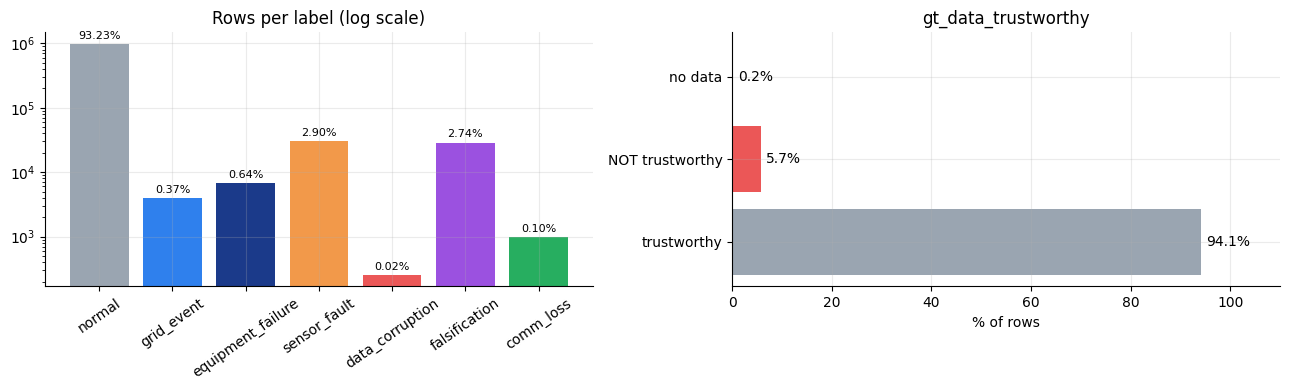

In [3]:
colors = {"normal": "#9aa5b1", "grid_event": "#2f80ed", "equipment_failure": "#1b3a8a", "sensor_fault": "#f2994a",
          "data_corruption": "#eb5757", "falsification": "#9b51e0", "comm_loss": "#27ae60"}
vc = df.gt_label.value_counts().reindex(colors)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(vc.index, vc.values, color=[colors[l] for l in vc.index]); ax[0].set_yscale("log")
ax[0].set_title("Rows per label (log scale)"); ax[0].tick_params(axis="x", rotation=35)
for i, v in enumerate(vc.values): ax[0].text(i, v * 1.2, f"{v / len(df) * 100:.2f}%", ha="center", fontsize=8)

tr = df.gt_data_trustworthy.map({1: "trustworthy", 0: "NOT trustworthy"}).fillna("no data").value_counts()
bars = ax[1].barh(tr.index, tr.values / len(df) * 100, color=["#9aa5b1", "#eb5757", "#27ae60"])
for b, v in zip(bars, tr.values / len(df) * 100): ax[1].text(v + 1, b.get_y() + b.get_height() / 2, f"{v:.1f}%", va="center")
ax[1].set_xlim(0, 110); ax[1].set_xlabel("% of rows"); ax[1].set_title("gt_data_trustworthy")
plt.tight_layout(); plt.show()

In [4]:
# every fault type and how many rows carry it
(df[df.gt_label != "normal"].groupby(["gt_label", "gt_subtype"]).size().rename("rows").to_frame())

rows
gt_label          gt_subtype                     
comm_loss         comm_dropout_burst          999
data_corruption   negative_value               33
                  saturation                   76
                  spike_gain                   47
                  unit_error_x1000            100
equipment_failure cable_fault                 182
                  cold_load_pickup            122
                  transformer_degradation    6345
                  transformer_trip             60
falsification     coordinated_fdi            7410
                  fdi_evasion                2894
                  fdi_inflate                3003
                  fdi_replay                 2721
                  fdi_scale                  4022
                  meter_zeroing               438
                  partial_reduction_bypass   7074
                  selective_bypass           1260
grid_event        cold_load_pickup            920
                  demand_surge                711
                  load_shedding               756
                  outage                      853
                  voltage_sag                 378
                  voltage_swell               302
sensor_fault      bias_step                  5988
                  clock_shift                1082
                  gain_drift                17528
                  stuck_value                 444
                  voltage_offset_drift       5463

## 4. The three neighborhoods

In [5]:
meters = df.drop_duplicates("meter_id")
summary = meters.groupby("node_id").agg(meters=("meter_id", "size"), feeders=("feeder_id", "nunique"),
                                         with_AC=("has_ac", "mean"), with_PV=("has_pv", "mean"),
                                         avg_distance_m=("distance_to_transformer_m", "mean"))
summary["with_AC"] *= 100; summary["with_PV"] *= 100
summary["avg_temp_c"] = df.groupby("node_id").temp_c.mean()
summary.round(1).rename(columns={"with_AC": "% with AC", "with_PV": "% with PV"})

,meters,feeders,% with AC,% with PV,avg_distance_m,avg_temp_c
node_id,,,,,,
N1,30,3,66.7,10.0,196.0,19.1
N2,15,2,73.3,20.0,416.1,20.3
N3,15,2,73.3,13.3,206.4,20.6


## 5. What normal consumption looks like

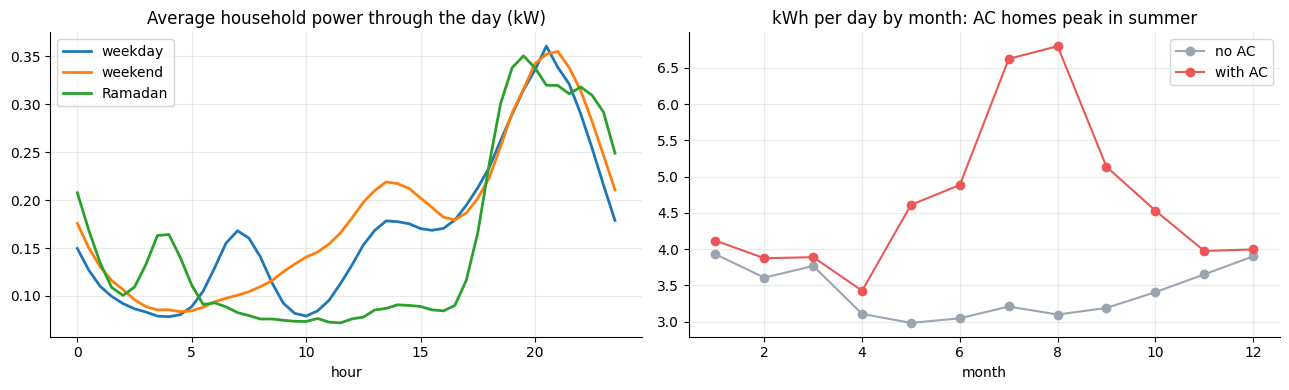

In [6]:
ok = df[(df.gt_data_trustworthy == 1) & (df.customer_class != "small_commercial")]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

prof = {"weekday": ok[(ok.is_weekend == 0) & (ok.is_ramadan == 0)], "weekend": ok[(ok.is_weekend == 1) & (ok.is_ramadan == 0)],
        "Ramadan": ok[ok.is_ramadan == 1]}
for name, d in prof.items(): ax[0].plot(d.groupby("hour").energy_kwh.mean() * 2, lw=2, label=name)
ax[0].set_title("Average household power through the day (kW)"); ax[0].set_xlabel("hour"); ax[0].legend()

m = ok[ok.customer_class != "res_small"].groupby(["month", "has_ac"]).energy_kwh.mean().unstack() * 48
m.columns = ["no AC", "with AC"]; m.plot(ax=ax[1], marker="o", color=["#9aa5b1", "#eb5757"])
ax[1].set_title("kWh per day by month: AC homes peak in summer"); ax[1].set_xlabel("month")
plt.tight_layout(); plt.show()

## 6. Physics holds: voltage and consistency

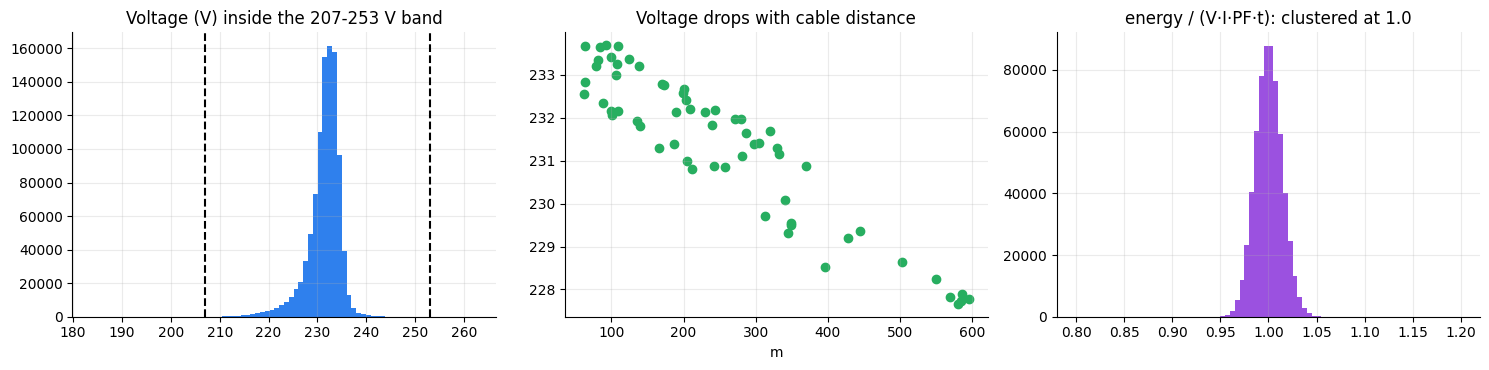

In [7]:
live = df[(df.gt_data_trustworthy == 1) & (df.voltage_v > 1)]
c = live[(live.energy_kwh > .05) & (live.pv_export_kwh == 0) & live.current_a.notna()]
ratio = c.energy_kwh / (c.voltage_v * c.current_a * c.power_factor * 0.5 / 1000)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(live.voltage_v, bins=80, color="#2f80ed"); ax[0].axvline(207, c="k", ls="--"); ax[0].axvline(253, c="k", ls="--")
ax[0].set_title("Voltage (V) inside the 207-253 V band")
d = live.groupby("meter_id").agg(v=("voltage_v", "mean"), dist=("distance_to_transformer_m", "first"))
ax[1].scatter(d.dist, d.v, color="#27ae60"); ax[1].set_title("Voltage drops with cable distance"); ax[1].set_xlabel("m")
ax[2].hist(ratio.clip(.8, 1.2), bins=80, color="#9b51e0"); ax[2].set_title("energy / (V·I·PF·t): clustered at 1.0")
plt.tight_layout(); plt.show()

## 7. Fault examples: reported vs. true

Orange is what the meter reported, grey is the true value.

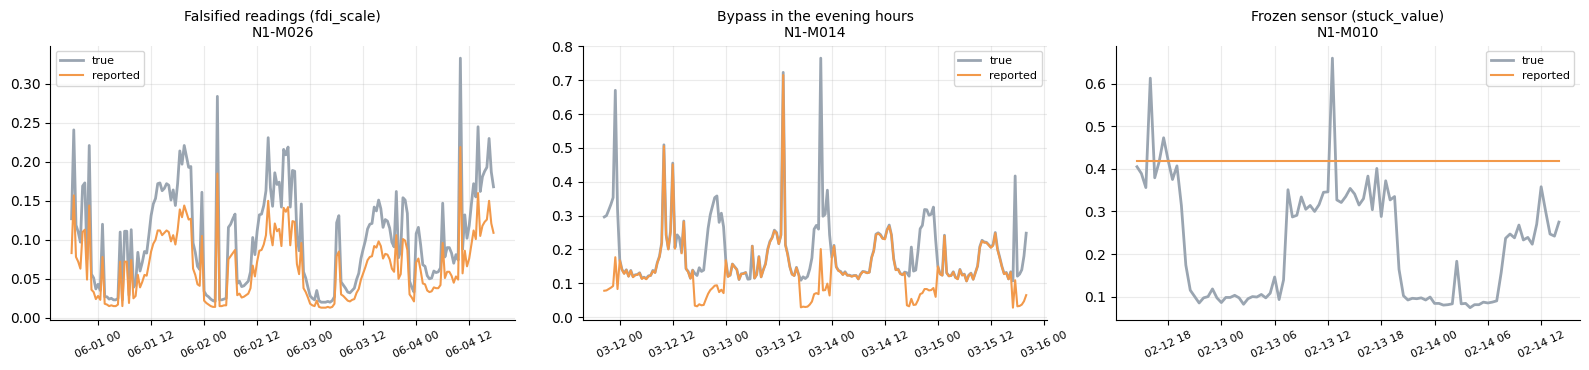

In [8]:
def example(subtype, days=3, zoom=False):
    e = df[df.gt_subtype == subtype]
    eid = e.groupby("gt_event_id").size().sort_values().index[-1]
    e = e[e.gt_event_id == eid]; meter = e.meter_id.iloc[0]
    mid = e.timestamp.min() + (e.timestamp.max() - e.timestamp.min()) / 2
    g = df[(df.meter_id == meter) & (df.timestamp.between(mid - pd.Timedelta(days=days), mid + pd.Timedelta(days=days)))]
    return meter, g

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for a, (sub, title) in zip(ax, [("fdi_scale", "Falsified readings (fdi_scale)"),
                                ("selective_bypass", "Bypass in the evening hours"),
                                ("stuck_value", "Frozen sensor (stuck_value)")]):
    meter, g = example(sub, days=2 if sub != "stuck_value" else 1)
    a.plot(g.timestamp, g.gt_true_energy_kwh, color="#9aa5b1", lw=2, label="true"); a.plot(g.timestamp, g.energy_kwh, color="#f2994a", label="reported")
    a.set_title(f"{title}\n{meter}", fontsize=10); a.tick_params(axis="x", rotation=25, labelsize=8); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 8. Genuine event vs. faulty sensor

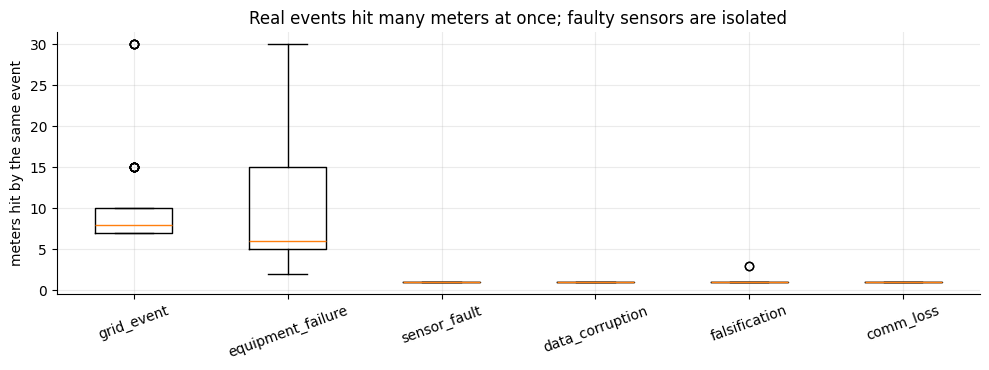

In [9]:
ev = df[df.gt_event_id != "none"].groupby("gt_event_id").agg(label=("gt_label", "first"), meters=("meter_id", "nunique"))
order = ["grid_event", "equipment_failure", "sensor_fault", "data_corruption", "falsification", "comm_loss"]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.boxplot([ev[ev.label == l].meters for l in order], labels=order)
ax.set_ylabel("meters hit by the same event"); plt.xticks(rotation=20)
ax.set_title("Real events hit many meters at once; faulty sensors are isolated")
plt.tight_layout(); plt.show()

## 9. The feeder meter reveals hidden problems

The meter at the head of each line sees the true flow. About 5 % of the energy is normally lost on the line; a bigger gap points at theft or biased meters.

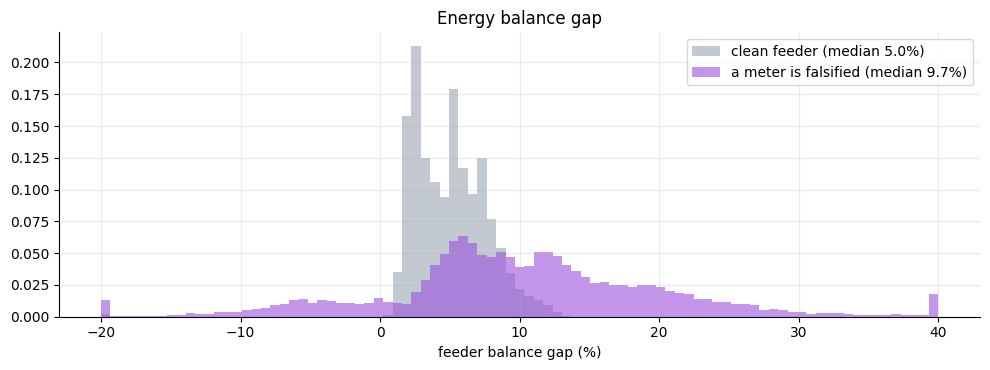

In [10]:
fd = df.drop_duplicates(["timestamp", "feeder_id"])
fd = fd[(fd.n_meters_reporting == fd.n_meters_total) & (fd.feeder_kwh_net > .3) & (fd.gt_feeder_label == "normal")]
fig, ax = plt.subplots(figsize=(10, 3.8))
bins = np.linspace(-20, 40, 90)
for d, lab, col in [(fd[(fd.gt_n_meters_falsified == 0) & (fd.gt_n_meters_sensor_fault == 0)], "clean feeder", "#9aa5b1"),
                    (fd[fd.gt_n_meters_falsified > 0], "a meter is falsified", "#9b51e0")]:
    ax.hist(d.energy_balance_gap_pct.clip(-20, 40), bins=bins, alpha=.6, density=True, color=col,
            label=f"{lab} (median {d.energy_balance_gap_pct.median():.1f}%)")
ax.set_xlabel("feeder balance gap (%)"); ax.legend(); ax.set_title("Energy balance gap")
plt.tight_layout(); plt.show()

## 10. How to use it

```python
gt   = [c for c in df.columns if c.startswith("gt_")]
X    = df.drop(columns=gt + ["annual_kwh_target", "fault_weight"])   # inputs (50 columns)
y    = df["gt_data_trustworthy"]                                     # 1 = trust, 0 = faulty, empty = no data
```

- Never use `gt_*` columns as inputs; they hold the answers.
- Split by **time** (train Jan–Aug, validate Sep–Oct, test Nov–Dec), not at random.
- Keep `gt_label` and `gt_subtype` to check that real events are not flagged as sensor faults and to score explanations.